# Wijayagunasekara L.A.V.D.S. (IT25100064) – Progress Review I
## Preprocessing Technique: Encoding Categorical Variables
**Group ID:** 2026-Y2-S1-MLB-B11G2-05 &nbsp;|&nbsp; **Member:** Wijayagunasekara L.A.V.D.S. &nbsp;|&nbsp; **Index No.:** IT25100064
**Module:** Artificial Intelligence and Machine Learning
**Dataset:** UCI *Letter Recognition* Data Set (20,000 instances, 16 numeric attributes + 1 categorical target `lettr`)



## 1. Technique Overview: Encoding Categorical Variables

Machine learning algorithms operate on numbers, so any categorical (text/label) column must be
converted to a numeric representation before it can be used. The three most common encodings are:

- **Label Encoding:** maps each category to an integer (`A → 0, B → 1, ...`). Simple and compact,
  but implicitly introduces an *ordinal* relationship between categories that may not exist.
- **One-Hot Encoding:** creates one new binary (0/1) column per category. Avoids implying a false
  order, at the cost of increasing dimensionality — one extra column per category.
- **Ordinal Encoding:** like label encoding, but deliberately used only when categories genuinely
  have a natural order (e.g. `low < medium < high`).

The right choice depends on (a) whether the categorical column is a *predictor* or the *target*, and
(b) whether the categories have a genuine order, and (c) how many distinct categories exist.


In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.preprocessing import LabelEncoder

pd.set_option('display.max_columns', 30)
sns.set_style('whitegrid')

COLUMN_NAMES = ['lettr', 'x-box', 'y-box', 'width', 'high', 'onpix', 'x-bar', 'y-bar',
                'x2bar', 'y2bar', 'xybar', 'x2ybr', 'xy2br', 'x-ege', 'xegvy', 'y-ege', 'yegvx']

df = pd.read_csv('../data/raw/letter-recognition.data', header=None, names=COLUMN_NAMES)
print("Dataset shape:", df.shape)
print("\nColumn dtypes:")
print(df.dtypes)


Dataset shape: (20000, 17)

Column dtypes:
lettr      str
x-box    int64
y-box    int64
width    int64
high     int64
onpix    int64
x-bar    int64
y-bar    int64
x2bar    int64
y2bar    int64
xybar    int64
x2ybr    int64
xy2br    int64
x-ege    int64
xegvy    int64
y-ege    int64
yegvx    int64
dtype: object


## 2. Justification for This Notebook

Inspecting the dtypes above shows that **all 16 predictor attributes are already numeric** — they
were pre-extracted as statistical moments and edge counts by the dataset's creators. The **only**
categorical column in the entire dataset is `lettr`, the **target** variable, which takes 26 distinct
values (the capital letters A–Z).

Although there is no categorical *predictor* to encode here, correctly encoding the categorical
**target** is still an essential preprocessing step: `scikit-learn` classifiers require target labels
in a specific numeric or string format depending on the metric/algorithm, and encoding is required
before we can compute a numeric confusion matrix, use `LabelEncoder`-dependent metrics, or feed the
target into any framework (e.g. Keras/TensorFlow for a possible neural-network baseline) that expects
integer class indices.


## 3. EDA Visualization: Class Distribution of the Target


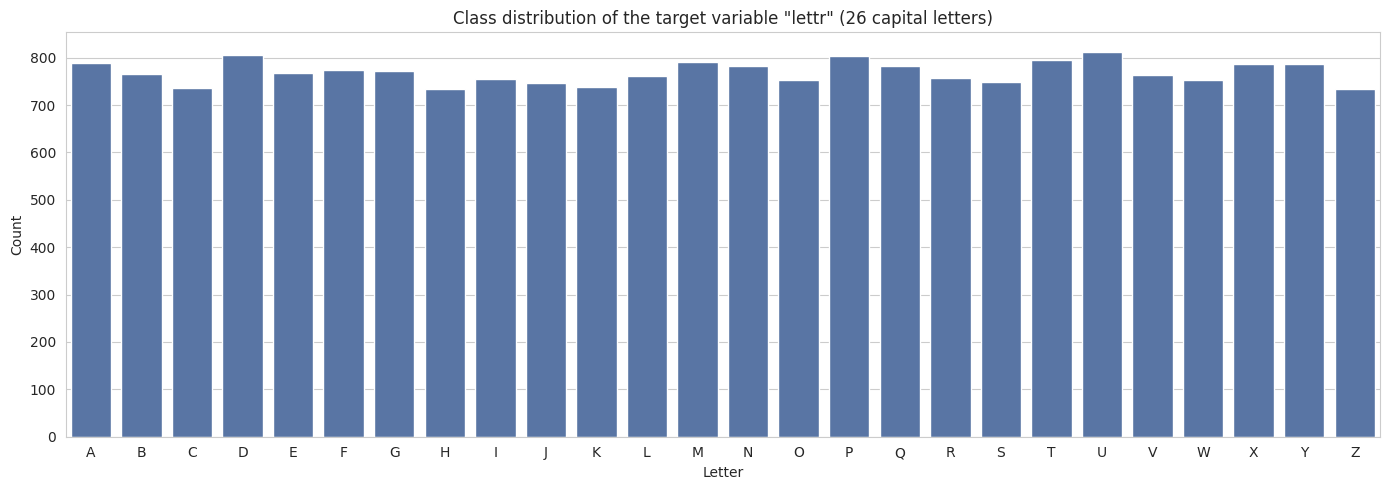

Smallest class: H (734 examples)
Largest class:  U (813 examples)
Mean examples per class: 769.2, Std: 23.2


In [2]:
fig, ax = plt.subplots(figsize=(14, 5))
order = sorted(df['lettr'].unique())
sns.countplot(x='lettr', data=df, order=order, color='#4C72B0', ax=ax)
ax.set_title('Class distribution of the target variable "lettr" (26 capital letters)')
ax.set_xlabel('Letter')
ax.set_ylabel('Count')
plt.tight_layout()
plt.savefig('../results/eda_visualizations/wijayagunasekara_class_distribution.png', dpi=110)
plt.show()

counts = df['lettr'].value_counts().sort_values()
print(f"Smallest class: {counts.index[0]} ({counts.iloc[0]} examples)")
print(f"Largest class:  {counts.index[-1]} ({counts.iloc[-1]} examples)")
print(f"Mean examples per class: {counts.mean():.1f}, Std: {counts.std():.1f}")


**Interpretation:** The 26 letter classes are close to evenly represented — every class has
somewhere between roughly 730 and 815 examples out of 20,000, so this is a near-perfectly balanced
multi-class problem. This matters for encoding: with a **nominal** (non-ordered) target that has this
many roughly-equal classes, we do not want an encoding that implies any letter is "greater than"
another, but we also do not want to explode the target into 26 separate one-hot columns, since
scikit-learn classifiers are designed to consume a single integer-encoded target column directly.


## 4. Implementation: Label Encoding the Target


In [3]:
label_encoder = LabelEncoder()
df['lettr_encoded'] = label_encoder.fit_transform(df['lettr'])

mapping = dict(zip(label_encoder.classes_, label_encoder.transform(label_encoder.classes_)))
print("Label encoding mapping (letter -> integer code):")
for letter, code_val in mapping.items():
    print(f"  {letter} -> {code_val}", end='   ')
    if (label_encoder.transform([letter])[0] + 1) % 6 == 0:
        print()

print("\n\nSample of the encoded column:")
print(df[['lettr', 'lettr_encoded']].head(8))


Label encoding mapping (letter -> integer code):
  A -> 0     B -> 1     C -> 2     D -> 3     E -> 4     F -> 5   
  G -> 6     H -> 7     I -> 8     J -> 9     K -> 10     L -> 11   
  M -> 12     N -> 13     O -> 14     P -> 15     Q -> 16     R -> 17   
  S -> 18     T -> 19     U -> 20     V -> 21     W -> 22     X -> 23   
  Y -> 24     Z -> 25   

Sample of the encoded column:
  lettr  lettr_encoded
0     T             19
1     I              8
2     D              3
3     N             13
4     G              6
5     S             18
6     B              1
7     A              0


## 5. Implementation: One-Hot Encoding (for Comparison)

We also demonstrate one-hot encoding of the same column to show the alternative representation and
its trade-offs, even though we will **not** carry it forward into the pipeline for this target.


In [4]:
one_hot = pd.get_dummies(df['lettr'], prefix='lettr')
print("One-hot encoded shape:", one_hot.shape, "(one column per letter)")
print("\nFirst 3 rows (showing only a few of the 26 one-hot columns):")
print(one_hot.iloc[:3, :6])


One-hot encoded shape: (20000, 26) (one column per letter)

First 3 rows (showing only a few of the 26 one-hot columns):
   lettr_A  lettr_B  lettr_C  lettr_D  lettr_E  lettr_F
0    False    False    False    False    False    False
1    False    False    False    False    False    False
2    False    False    False     True    False    False


## 6. Discussion: Which Encoding Should the Pipeline Use?

| | Label Encoding | One-Hot Encoding |
|---|---|---|
| Output columns | 1 | 26 |
| Implies false order? | Only matters if fed as a **predictor** to an order-sensitive model | Never |
| Works directly with `sklearn` classifiers as `y`? | Yes (this is the expected format) | No — must be reversed |
| Memory footprint | Small | 26× larger for this column alone |

Since `lettr` is the **target**, not a predictor, tree-based models, SVMs and most `scikit-learn`
classifiers are specifically designed to accept a single label-encoded integer column as `y` and do
not assume any ordinal relationship between class indices during classification — the "false order"
concern with label encoding is a real risk for **predictor** columns, but not for a classifier's
target. One-hot encoding the target would in fact be counter-productive here, since it would turn a
single multi-class classification problem into 26 separate binary columns that a standard classifier
cannot consume directly.

**Decision:** the group pipeline will use the **label-encoded `lettr_encoded`** column as `y` for all
downstream models.


## 7. Conclusion

- All 16 predictors are already numeric; the only categorical variable in this dataset is the
  26-class target `lettr`.
- We label-encoded the target (`lettr_encoded`, values 0–25) and also demonstrated one-hot encoding
  for comparison.
- Label encoding is the correct and standard choice for a classification **target** in `scikit-learn`,
  and this is the encoding carried forward into `group_pipeline.ipynb`.
